## STREAMLINES OF FLUID AROUND A CYLINDER

In [2]:
from matplotlib import pyplot as plt
import numpy as np
import scipy

In [1]:
from matplotlib.animation import PillowWriter

In [3]:
a = 1. #radius of cylinder
U = 1. #velocity at large distances

From the continuity equation, if we set $\rho$ constant, we get

$$ \frac{\partial \rho}{\partial t} + \nabla \cdot (\rho \vec{u}) = 0, \quad \nabla \cdot \vec{u} = 0$$

From no vorticity we have 

$$ \nabla \times \vec{u} = 0, \quad u^\alpha = \nabla^\alpha \varphi$$

Plugging this into the divergence-free condition we have

$$ \square \varphi = 0$$

$$ \square \varphi = \frac{1}{r} \partial_r \left( r g^{rr} \partial_r \varphi \right) + \frac{1}{r} \partial_\phi \left(r g^{\phi \phi} \partial_\phi \varphi \right) = 0$$

$$ \frac{1}{r} \partial_r \left( r \partial_r \varphi \right) + \frac{1}{r^2} \partial^2_\phi \varphi = 0$$

The above is solved by

$$ \varphi = U \left( r + \frac{a^2}{r}\right)cos \phi$$

for the boundary conditions that $u^r(r=a, \phi) = 0$ and $u^r(r \rightarrow \infty, \phi) = U$

The explicit velocities (in the Riemann basis) are

$$ u^r = \partial_r \varphi = U \left( 1 - \frac{a^2}{r^2}\right) cos \phi$$

$$ u^\phi = \frac{1}{r^2} \partial_\phi \varphi = - \frac{U}{r^2} \left( r + \frac{a^2}{r}\right) sin \phi $$

Projecting to the Cartesian prthonormal basis we have

$$ u^x = \frac{\partial x}{\partial x^\beta} u^\beta = cos \phi u^r - r sin \phi u^\phi$$

$$ u^y = sin \phi u^r + r cos \phi u^\phi $$

## Static Plot with Bernoulli Pressure no Vorticity

In [4]:
x = np.linspace(-3*a,3*a,200)
y = np.linspace(-3*a,3*a,200)
X,Y = np.meshgrid(x,y)

In [5]:
R = np.sqrt(X**2 + Y**2)
phi = np.arctan2(Y,X)

In [6]:
Ur = U*(1 - a**2./R**2.)*np.cos(phi)
Uphi = (1/R**2.)*U*(R + a**2./R)*-np.sin(phi)

Ux = np.cos(phi)*Ur - R*np.sin(phi)*Uphi
Uy = np.sin(phi)*Ur + R*np.cos(phi)*Uphi

In [16]:
p_inf = 1.
rho = 1.

p = p_inf + (1/2)*rho*(U**2. - Ux**2. - Uy**2.)

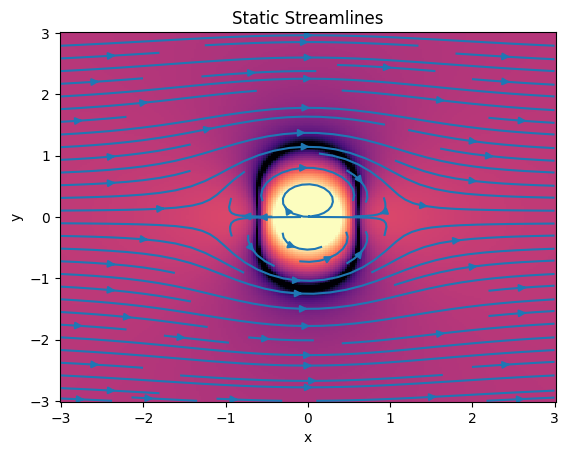

In [34]:
plt.streamplot(X,Y,Ux,Uy)
plt.pcolormesh(X, Y, np.log10(np.abs(p)), vmin=-1, vmax =1, cmap='magma')
plt.xlabel(r'x')
plt.ylabel(r'y')
plt.title('Static Streamlines')
plt.show()

## Tracer Particles no Vorticity

In [8]:

def calc_ux_uy(x,y):
    r = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y,x)
    ur = U*(1 - a**2./r**2.)*np.cos(phi)
    uphi = (1/r**2.)*U*(r + a**2./r)*-np.sin(phi)

    ux = np.cos(phi)*ur - r*np.sin(phi)*uphi
    uy = np.sin(phi)*ur + r*np.cos(phi)*uphi

    return ux, uy


In [9]:
class tracer_particle():
    def __init__(self, x0, y0, t):
        self.t = t
        self.dt = (self.t[-1] - self.t[0])/(len(t) - 1)
        self.x = np.zeros(len(t))
        self.y = np.zeros(len(t))
        self.x[0] = x0
        self.y[0] = y0

    #do RK4 to evolve particles
    def trace(self):
        for i in range(0, len(self.t)-1):
            #k1
            x_k1, y_k1 = calc_ux_uy(self.x[i], self.y[i])

            #k2
            x_k2, y_k2 = calc_ux_uy(self.x[i] + x_k1*self.dt/2, self.y[i] + y_k1*self.dt/2)

            #k3
            x_k3, y_k3 = calc_ux_uy(self.x[i] + x_k2*self.dt/2, self.y[i] + y_k2*self.dt/2)

            #k4
            x_k4, y_k4 = calc_ux_uy(self.x[i] + x_k3*self.dt, self.y[i] + y_k3*self.dt)

            self.x[i+1] = self.x[i] + self.dt*(x_k1 + 2*x_k2 + 2*x_k3 + x_k4)/6
            self.y[i+1] = self.y[i] + self.dt*(y_k1 + 2*y_k2 + 2*y_k3 + y_k4)/6



In [10]:
#trace a set of particles


x0 = -3*a
y0 = np.linspace(-2*a,2*a,40)
tmax = 10
t = np.linspace(0, tmax, int(tmax/1e-2 + 1) )

particles = []
for i in range(0, len(y0)):
    particles.append(tracer_particle(x0, y0[i], t))
    particles[i].trace()
    print('Traced particle '+str(i+1))


Traced particle 1
Traced particle 2
Traced particle 3
Traced particle 4
Traced particle 5
Traced particle 6
Traced particle 7
Traced particle 8
Traced particle 9
Traced particle 10
Traced particle 11
Traced particle 12
Traced particle 13
Traced particle 14
Traced particle 15
Traced particle 16
Traced particle 17
Traced particle 18
Traced particle 19
Traced particle 20
Traced particle 21
Traced particle 22
Traced particle 23
Traced particle 24
Traced particle 25
Traced particle 26
Traced particle 27
Traced particle 28
Traced particle 29
Traced particle 30
Traced particle 31
Traced particle 32
Traced particle 33
Traced particle 34
Traced particle 35
Traced particle 36
Traced particle 37
Traced particle 38
Traced particle 39
Traced particle 40


In [11]:
len(t)

1001

In [39]:
def plot_frame(index, ax):

    
   
    for i in range(0, len(particles)):
        ax.plot(particles[i].x[0:index+1], particles[i].y[0:index+1], c='red')
   
    ax.annotate(f'Time: {t[index]:.2f}', (-3, 2.25), c='white')
    
    ax.set_xlim([-3.5,3.5])
    ax.set_ylim([-2.5,2.5])
    ax.set_xticks([])
    ax.set_yticks([])
   

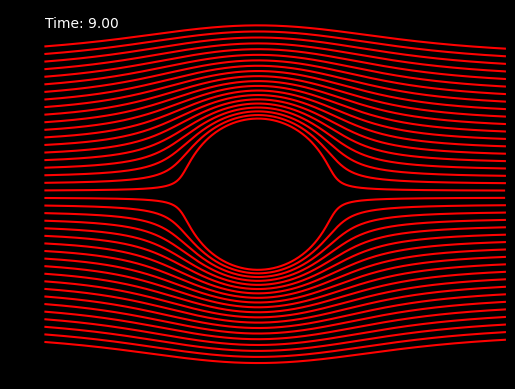

In [40]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')
plot_frame(900,ax)
plt.show()

In [14]:
metadata = dict(title='Movie', artist ='ayush_roy')
writer = PillowWriter(fps=10, metadata = metadata)

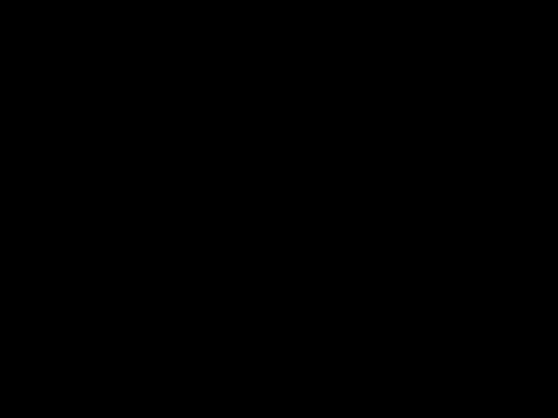

In [15]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

with writer.saving(fig, 'streamlines_no_vorticity.gif',100):
    for i in range(0, len(t)):
        if i%4 == 0:
            plot_frame(i, ax)
            writer.grab_frame()
            plt.cla()
            

## Static Streamlines with Bernoulli with Vorticity

Update the potential to be

$$ \varphi = \varphi_0 + \frac{\Gamma \phi}{2 \pi}$$

This changes the $\phi$ component of $\vec{u}$, but $\nabla_\alpha u^\alpha = \square \varphi = 0$ still, and $\nabla \times \vec{u} = 0$ everywhere except $r=0$

However, at $r=0$, $\nabla \times \vec{u} = \Gamma \delta(x)\delta(y) \hat{z}$. This can be checked with Stokes' Law 

$$ \int \vec{u} \cdot \vec{dl} = \int \int \nabla \times \vec{u} \cdot \vec{dA} = \Gamma $$

Here $\Gamma$ is the circulation and is a global quantity which creates lift/net vertical force on the obstacle

In [41]:
#new Uphi
Gamma = 1.
Uphi = Uphi + Gamma/(2*np.pi)

Ux = np.cos(phi)*Ur - R*np.sin(phi)*Uphi
Uy = np.sin(phi)*Ur + R*np.cos(phi)*Uphi

In [42]:
p_inf = 1.
rho = 1.

p = p_inf + (1/2)*rho*(U**2. - Ux**2. - Uy**2.)

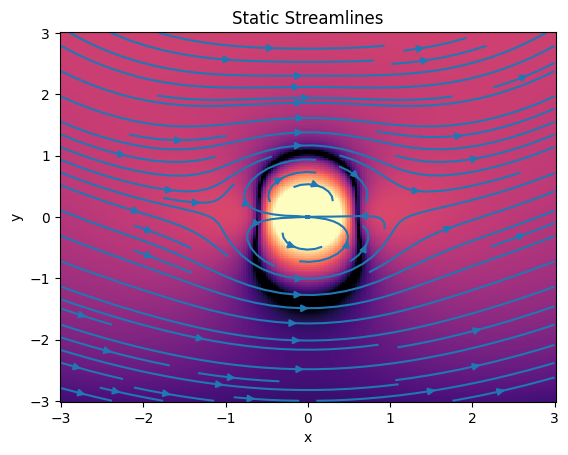

In [43]:
plt.streamplot(X,Y,Ux,Uy)
plt.pcolormesh(X, Y, np.log10(np.abs(p)), vmin=-1, vmax =1, cmap='magma')
plt.xlabel(r'x')
plt.ylabel(r'y')
plt.title('Static Streamlines')
plt.show()

## Tracer Particles with Vorticity

In [44]:
def calc_ux_uy(x,y):
    r = np.sqrt(x**2 + y**2)
    phi = np.arctan2(y,x)
    ur = U*(1 - a**2./r**2.)*np.cos(phi)
    uphi = (1/r**2.)*U*(r + a**2./r)*-np.sin(phi) + Gamma/(2*np.pi)

    ux = np.cos(phi)*ur - r*np.sin(phi)*uphi
    uy = np.sin(phi)*ur + r*np.cos(phi)*uphi

    return ux, uy

In [45]:
#trace a set of particles


x0 = -3*a
y0 = np.linspace(-2*a,2*a,40)
tmax = 10
t = np.linspace(0, tmax, int(tmax/1e-2 + 1) )

particles = []
for i in range(0, len(y0)):
    particles.append(tracer_particle(x0, y0[i], t))
    particles[i].trace()
    print('Traced particle '+str(i+1))

Traced particle 1
Traced particle 2
Traced particle 3
Traced particle 4
Traced particle 5
Traced particle 6
Traced particle 7
Traced particle 8
Traced particle 9
Traced particle 10
Traced particle 11
Traced particle 12
Traced particle 13
Traced particle 14
Traced particle 15
Traced particle 16
Traced particle 17
Traced particle 18
Traced particle 19
Traced particle 20
Traced particle 21
Traced particle 22
Traced particle 23
Traced particle 24
Traced particle 25
Traced particle 26
Traced particle 27
Traced particle 28
Traced particle 29
Traced particle 30
Traced particle 31
Traced particle 32
Traced particle 33
Traced particle 34
Traced particle 35
Traced particle 36
Traced particle 37
Traced particle 38
Traced particle 39
Traced particle 40


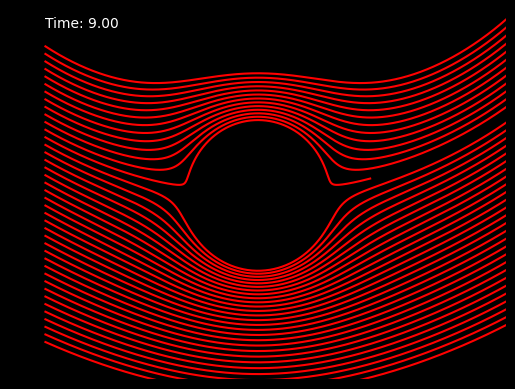

In [46]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')
plot_frame(900,ax)
plt.show()

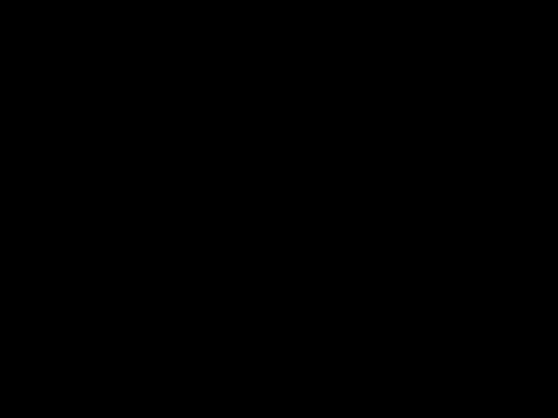

In [47]:
fig, ax = plt.subplots()
ax.set_facecolor('black')
fig.patch.set_facecolor('black')

with writer.saving(fig, 'streamlines_with_vorticity.gif',100):
    for i in range(0, len(t)):
        if i%4 == 0:
            plot_frame(i, ax)
            writer.grab_frame()
            plt.cla()